# S-GRPO by Hand: Teaching a Reasoning Model to Exit Early

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/sgrpo_early_exit.ipynb)

**A simple, CPU-only companion** for *GRPO, Then and Now* — the fourth method in the guide's
`GRPO → DAPO → DisCO → S-GRPO` arc.

> **The design choice it responds to.** Standard GRPO rewards only the *final* answer (0/1),
> so it never regulates the reasoning *in between* — and reasoning models **overthink**,
> often drifting into errors after they already had the answer. **S-GRPO** (Serial-Group
> Decaying-Reward Policy Optimization; Dai, Yang & Si, NeurIPS 2025, arXiv:2505.07686)
> changes exactly two pieces: it forces the model to answer at several **exit points along
> one chain-of-thought** (a *serial group*) and pays a **decaying reward**: the earliest correct
> exit earns 1, later correct exits earn 1/2, 1/4, ... The model learns to stop as soon as its
> reasoning is sufficient.

We follow the same rhythm as the DAPO and DisCO companion notebooks:
**predict → inspect → optimize → explain**.

## The one equation

For each answer in the serial group, walked from the earliest exit to the full chain:

$$ r^i = \begin{cases}\dfrac{1}{2^{\,N_{\text{right}}-1}} & \text{if answer } C^i \text{ is correct}\\[4pt] 0 & \text{otherwise}\end{cases}, \qquad \hat A_i = r_i - \text{mean}(r) $$

where $N_{\text{right}}$ is the number of correct answers seen so far (earliest first).
Note S-GRPO **drops** GRPO's division by the standard deviation, for stability.

**Prerequisites:** softmax, expectations, a policy gradient (the GRPO deck covers them).
**Requirements:** NumPy + Matplotlib. No GPU, no LLM, runs in seconds.

**How to use this notebook** (about 15 minutes): run the cells in order. The last code cell is an
optional exploration. The companion deck is `../slides/sgrpo_intro.html`.

> **Scope note.** This is a deliberately tiny, self-contained *analogy* of S-GRPO on a toy
> "when to stop thinking" problem, not a language-model training run. It isolates the two
> ideas that define S-GRPO — the serial group and the decaying reward — so you can see them
> work end to end. See the paper for the full method and large-scale results.

In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from grpo_lab import plots
from grpo_lab.objectives import softmax

In [2]:
def decaying_rewards(correct):
    """S-GRPO's Decaying Reward Strategy (paper Eq. 1).

    `correct` is ordered from the EARLIEST exit to the full chain.
    The k-th correct answer (counting from the front) earns 1 / 2**(k-1);
    incorrect answers earn 0.
    """
    r = np.zeros(len(correct), dtype=float)
    n_right = 0
    for i, ok in enumerate(correct):
        if ok:
            n_right += 1
            r[i] = 1.0 / (2 ** (n_right - 1))
    return r


def serial_advantages(r):
    """Serial-group advantage: reward minus the group mean (no std, unlike GRPO)."""
    return r - r.mean()


# Quick sanity check on the paper's example pattern: [wrong, correct, correct, correct, correct]
_demo = decaying_rewards([False, True, True, True, True])
print("rewards :", np.round(_demo, 3))          # -> [0, 1, 0.5, 0.25, 0.125]
print("advantages:", np.round(serial_advantages(_demo), 3))

rewards : [0.    1.    0.5   0.25  0.125]
advantages: [-0.375  0.625  0.125 -0.125 -0.25 ]


## Step 1 — Predict *(about 2 min)*

Imagine one reasoning chain with **5 exit points**, ordered from the earliest (least
thinking) to the full chain (most thinking):

`exit@20%  ·  exit@40%  ·  exit@60%  ·  exit@80%  ·  full CoT`

Suppose the model is **wrong** if it exits at 20% (not enough reasoning yet), but
**correct** at every later exit. The forced answers are therefore:

`[wrong, correct, correct, correct, correct]`

**Before running the next cell, predict:**

1. Which exit will receive the **largest reward**?
2. Which exit will receive the **largest (most positive) advantage** — i.e. which one does
   the S-GRPO gradient push the model toward?
3. What happens to the advantage of the *full CoT* exit?

## Step 2 — Inspect *(about 5 min)*

![S-GRPO serial group: one chain of thought is cut at 20, 40, 60 and 80% and at its end; the answers wrong, correct, correct, correct, correct earn rewards 0, 1, 1/2, 1/4 and 1/8, giving advantages -0.375, +0.625, +0.125, -0.125 and -0.25 around the mean reward 0.375.](attachment:F12_s_grpo_serial_group.png)

The next two cells score that serial group with the decaying reward, subtract the group mean to get each exit's advantage, and plot both. Compare the output with your predictions.

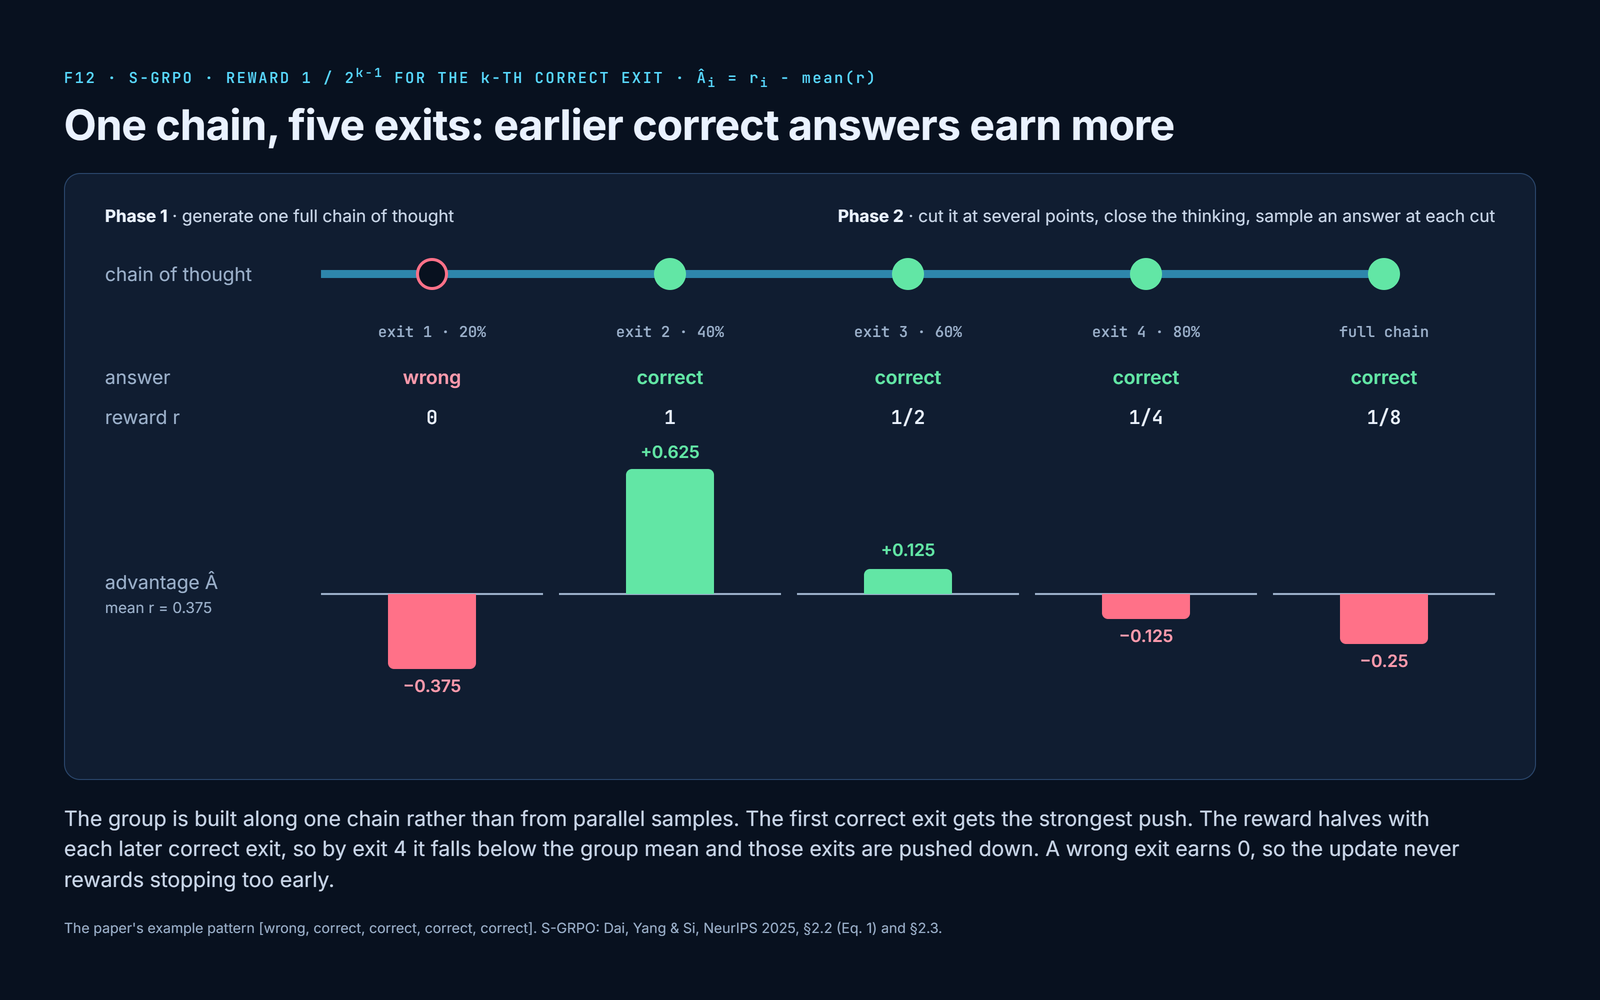

In [3]:
# === Step 2 — Inspect: build the serial group and score it ===

labels  = ["exit@20%", "exit@40%", "exit@60%", "exit@80%", "full CoT"]
correct = [False,      True,       True,       True,        True]      # forced-answer correctness

r   = decaying_rewards(correct)
adv = serial_advantages(r)

print(f"{'exit':<10}{'correct?':<10}{'reward':>8}{'advantage':>12}")
print("-" * 40)
for lab, ok, ri, ai in zip(labels, correct, r, adv):
    print(f"{lab:<10}{str(ok):<10}{ri:>8.3f}{ai:>+12.3f}")
print("-" * 40)
print(f"{'mean(r)':<20}{r.mean():>8.3f}")
print(f"most-reinforced exit: {labels[int(np.argmax(adv))]}")


exit      correct?    reward   advantage
----------------------------------------
exit@20%  False        0.000      -0.375
exit@40%  True         1.000      +0.625
exit@60%  True         0.500      +0.125
exit@80%  True         0.250      -0.125
full CoT  True         0.125      -0.250
----------------------------------------
mean(r)                0.375
most-reinforced exit: exit@40%


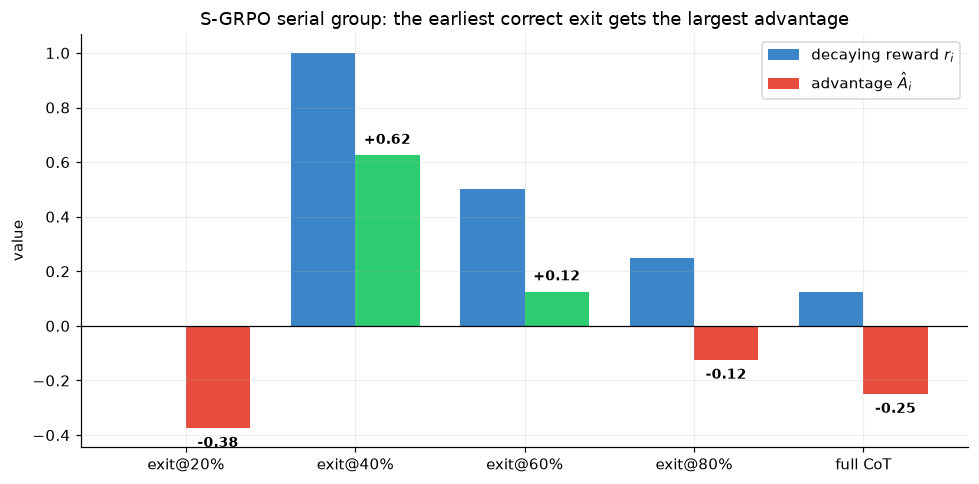

In [4]:
# Reward and advantage of every exit in the serial group
plots.serial_group(labels, r, adv)

**What you should see.** The `exit@40%` answer — the *earliest correct* one — gets reward
`1.0` and the largest positive advantage (`+0.625`). Later correct exits still get positive
reward but it is halved each time (`0.5, 0.25, 0.125`), and once the group mean is
subtracted the *full CoT* exit actually lands with a **negative** advantage. The wrong
`exit@20%` gets reward `0` and a negative advantage.

The gradient therefore says: *"produce the correct answer at 40% and stop."* That is
exactly the "early exit" behaviour S-GRPO is designed to induce — and note it is driven
purely by the **shape of the reward**, not by any explicit length penalty.

## Step 3 — Optimize *(about 8 min)*

The worked example above had a single fixed rollout. Now let's *train* a tiny policy and
watch early exiting emerge under a **realistic accuracy curve** — one with a genuine
trade-off, so "accuracy is preserved" is something we *demonstrate*, not assume.

**Toy setup.** A model reasons in up to `N = 8` steps. At each depth we can force an answer,
and whether that answer is correct is **probabilistic**. Critically, accuracy is
**non-monotonic in reasoning length** — the whole reason S-GRPO exists:

- **Too early** → not enough reasoning, likely *wrong* (low `P(correct)`).
- **Around the sweet spot** → reasoning is sufficient, likely *right* (high `P(correct)`).
- **Too late** → the model **overthinks** and drifts into errors, so `P(correct)` slips
  back down.

So exiting early is genuinely *tempting* (bigger decaying reward) but also *risky* (a wrong
early answer earns 0). The policy is a categorical distribution $\pi$ over *where to exit*
(depth `1..N`) — a stand-in for the model's tendency to emit "`</think>` then answer."

Each step we draw `G` stochastic serial-group rollouts, score each with the S-GRPO decaying
reward, average the advantages, and take one softmax policy-gradient step toward
high-advantage exits:

$$ \text{logit}_j \mathrel{+}= \eta\, \pi_j\big(\hat A_j - \textstyle\sum_k \pi_k \hat A_k\big) $$

We track the **expected exit depth** (reasoning length) and the **true accuracy**
$\sum_d \pi_d\, P(\text{correct}\mid d)$, and compare against a model that *always uses the
full chain*.

In [5]:
# === Step 3 — train a toy exit policy under a realistic (non-monotonic) accuracy curve ===

np.random.seed(0)
N      = 8
depths = np.arange(1, N + 1)

# Accuracy rises with reasoning... then OVERTHINKING (past depth 4) drags it back down.
rise      = 1.0 / (1.0 + np.exp(-(depths - 2.8) / 0.5))   # more thinking -> more likely right
overthink = 0.03 * np.maximum(0, depths - 4)              # ...but too much thinking hurts
p_correct = np.clip(rise - overthink, 0.0, 1.0)           # P(forced answer at each depth is correct)

print("depth       :", depths.tolist())
print("P(correct)  :", np.round(p_correct, 2).tolist())
print(f"'always full chain' baseline -> depth {N}, accuracy {p_correct[-1] * 100:.1f}%\n")

depth       : [1, 2, 3, 4, 5, 6, 7, 8]
P(correct)  : [0.03, 0.17, 0.6, 0.92, 0.96, 0.94, 0.91, 0.88]
'always full chain' baseline -> depth 8, accuracy 88.0%



In [6]:
lr, steps, G = 5.0, 400, 16
logits = np.zeros(N)                     # start uniform over exit depths
hist_depth, hist_acc = [], []
for t in range(steps):
    pi = softmax(logits)
    # average the S-GRPO advantage over G stochastic serial-group rollouts
    adv = np.zeros(N)
    for _ in range(G):
        correct = np.random.rand(N) < p_correct           # this chain's forced-answer correctness
        adv += serial_advantages(decaying_rewards(correct))
    adv /= G
    # softmax policy-gradient step toward high-advantage exits
    logits += lr * pi * (adv - np.dot(pi, adv))
    hist_depth.append(np.dot(pi, depths))                  # expected reasoning length
    hist_acc.append(np.dot(pi, p_correct))                 # true accuracy of the chosen exit

start:  expected exit depth = 4.50,  accuracy = 67.5%
end:    expected exit depth = 4.00,  accuracy = 91.6%
vs 'always full chain': 50% shorter reasoning, accuracy +3.6 points


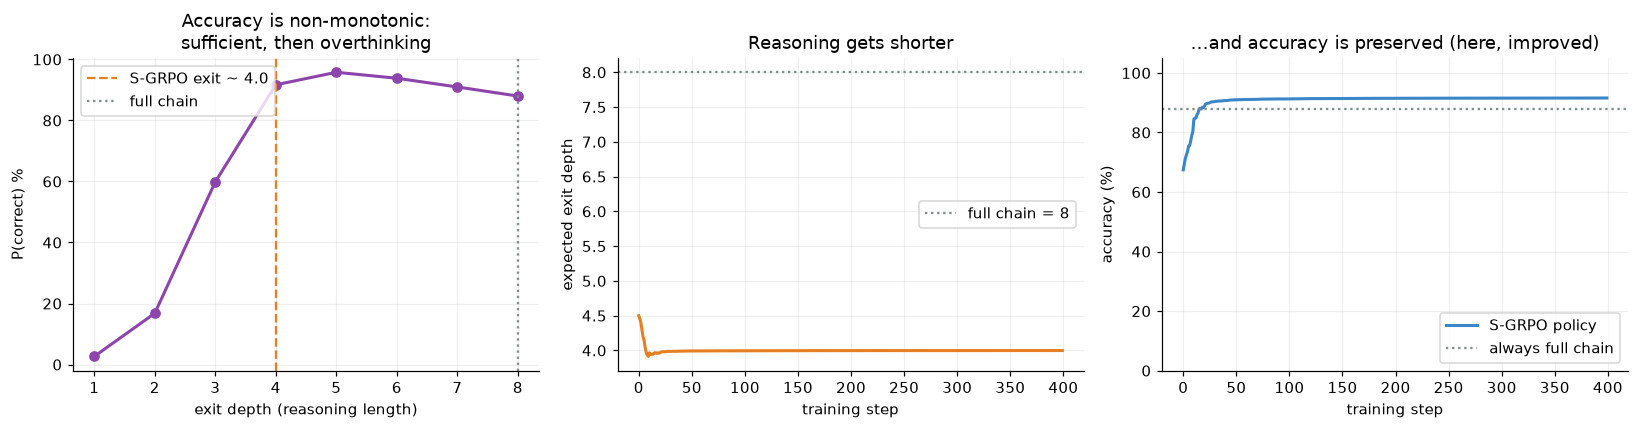

In [7]:
pi = softmax(logits)
exit_depth, policy_acc = np.dot(pi, depths), np.dot(pi, p_correct)
print(f"start:  expected exit depth = {hist_depth[0]:.2f},  accuracy = {hist_acc[0] * 100:.1f}%")
print(f"end:    expected exit depth = {exit_depth:.2f},  accuracy = {policy_acc * 100:.1f}%")
print(f"vs 'always full chain': {(1 - exit_depth / N) * 100:.0f}% shorter reasoning, "
      f"accuracy {(policy_acc - p_correct[-1]) * 100:+.1f} points")
plots.exit_policy_training(depths, p_correct, exit_depth, hist_depth, hist_acc)

## Step 4 — Explain *(about 5 min)*

The policy converges onto the **earliest depth whose answer is reliably correct** (~depth 4
here), the *knee* of the accuracy curve. Expected reasoning length drops ~50% versus a model
that always runs the full 8-step chain, and true accuracy actually **goes up a few points**,
because stopping early avoids the overthinking region where the full chain drifts into
errors. Crucially this was *not* baked in: correctness was stochastic and non-monotonic, so
the shorter policy had to *earn* its accuracy.

Two design choices produce this, and both come straight from the reward's shape:

- **Exponential decay for correct answers** makes the *earliest* correct exit the single
  most-reinforced action, pulling the policy toward stopping sooner.
- **Zero (not negative) reward for wrong answers** means a too-early *wrong* exit is never
  more attractive than a correct one — so the policy shortens only up to the point where
  answers are still reliable, and no further. Correctness first, brevity second.

The NeurIPS 2025 proceedings report the same efficiency–accuracy pattern at scale: **across
the evaluated model/benchmark settings**, S-GRPO reduces sequence length by **40.4–61.1%**
while improving absolute accuracy by **0.72–3.92 percentage points**. The five benchmarks
are GSM8K, AIME 2024, AMC 2023, MATH-500, and GPQA Diamond. These are overall ranges, not
per-benchmark values.

### Optional explorations (no reference solutions)

1. **Turn off overthinking.** Set `overthink = 0`. Now longer is never worse — does the
   policy still shorten? To what depth, and what accuracy does it sacrifice relative to the
   nearly perfect full chain? This exposes the efficiency–accuracy trade-off that the main
   non-monotonic example avoids.
2. **Make the sweet spot later.** Shift the ramp with `-(depths - 5.0)/0.5`. Where does the
   policy exit now, and how much reasoning does it save?
3. **Linear instead of exponential decay.** Replace `decaying_rewards` with a linear rule
   (`r = max(0, 1 - 0.2*(k-1))` for the `k`-th correct answer). Does early exiting emerge as
   sharply? Why does the *shape* of the decay matter?

In [8]:
# === Optional exploration: turn off the overthinking penalty and re-train ===
# Expectation: the policy still shortens because early correct exits pay more, but now it
# sacrifices accuracy relative to the nearly perfect full chain. Quantify that trade-off.

def train_exit_policy(p_correct, lr=5.0, steps=400, G=16, seed=0):
    """Train the toy S-GRPO exit policy for a given accuracy curve; return (depth, acc, pi)."""
    np.random.seed(seed)
    n = len(p_correct)
    depths = np.arange(1, n + 1)
    logits = np.zeros(n)
    for _ in range(steps):
        pi = softmax(logits)
        adv = np.zeros(n)
        for _ in range(G):
            adv += serial_advantages(decaying_rewards(np.random.rand(n) < p_correct))
        adv /= G
        logits += lr * pi * (adv - np.dot(pi, adv))
    pi = softmax(logits)
    return float(np.dot(pi, depths)), float(np.dot(pi, p_correct)), pi


# TODO: build a MONOTONIC accuracy curve (overthink = 0) and compare to the full chain.
# rise      = 1.0 / (1.0 + np.exp(-(depths - 2.8) / 0.5))
# p_mono    = rise                     # <- no overthinking penalty
# d, acc, _ = train_exit_policy(p_mono)
# print(f"exit depth {d:.2f}, accuracy {acc*100:.1f}% vs full chain {p_mono[-1]*100:.1f}%")

## Takeaway

![Reported results: average Pass@1 over six math benchmarks for GRPO versus the best DisCO variant (1.5B: 0.457 vs 0.533; 7B: 0.592 vs 0.627; Llama 8B: 0.516 vs 0.584), and S-GRPO's 40.4 to 61.1% shorter reasoning with an accuracy change of +0.72 to +3.92 points.](attachment:F14b_disco_and_s_grpo_results.png)

**S-GRPO changes the group and the reward, nothing else.** Swap GRPO's *parallel group*
(many full chains) for a *serial group* (many early exits along one chain), and swap the
0/1 outcome reward for a decaying $1/2^{\,N_{\text{right}}-1}$ that pays more for being right
sooner. The same clipped policy-gradient update then teaches the model to *stop thinking
once it is sufficient* — cutting inference cost without sacrificing accuracy.

> *Same verifier, same optimizer — a serial group and a decaying reward turn "be correct"
> into "be correct as early as possible."*

See the interactive slide deck: `../slides/sgrpo_intro.html`.

## References

- **S-GRPO** — Dai, Yang & Si (2025). *S-GRPO: Early Exit via Reinforcement Learning in
  Reasoning Models.* NeurIPS 2025. arXiv:2505.07686.
- **GRPO** — Shao et al. (2024). *DeepSeekMath.* arXiv:2402.03300.
- Companion notebooks in this lab: `01_grpo_core.ipynb`, `02_failure_lab.ipynb`, `dapo_four_fixes.ipynb`,
  `disco_three_fixes.ipynb`.
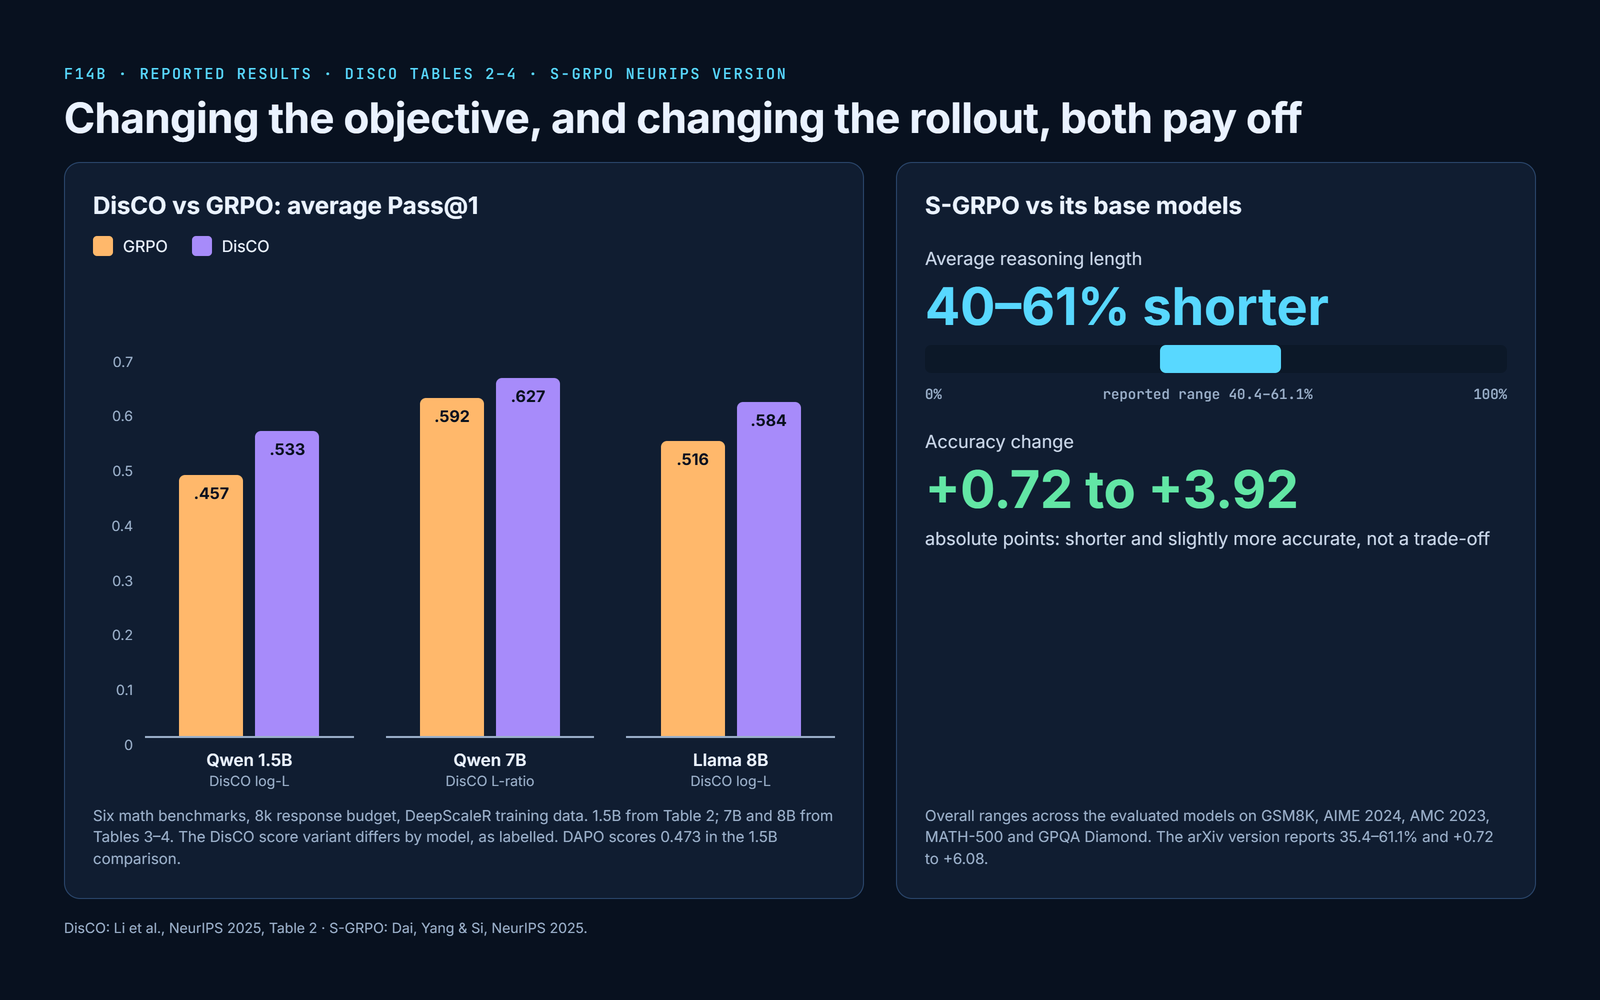